# Supermarket Sales Prediction: Data Analysis & ML
_By Mostafa Saad

## Import Library

In [1]:
# Import all library i used
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import SGDRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/supermarket-sales/supermarket_sales - Sheet1.csv


##  Data Description


In [2]:
#load data
df=pd.read_csv('/kaggle/input/supermarket-sales/supermarket_sales - Sheet1.csv')

In [3]:
#View the data
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [4]:
# Check data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

In [5]:
# This function provides summary statistics of the dataset
df.describe()

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000


In [6]:
#Name of columns
df.columns

Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date',
       'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income',
       'Rating'],
      dtype='object')

## Data Visualization & Plots


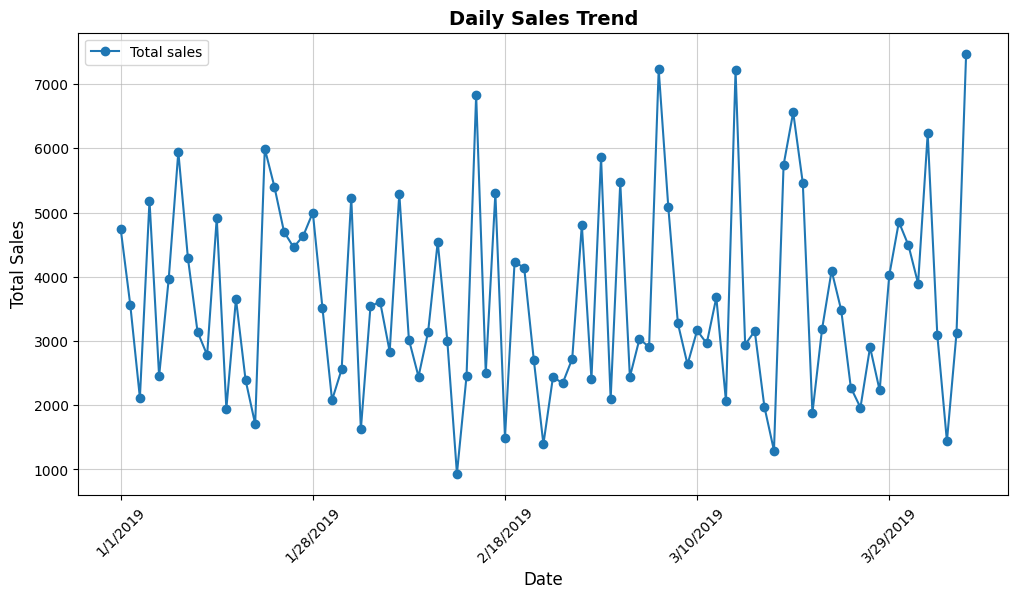

In [7]:
# Sum sales per day
sales_per_day= df.groupby('Date')['Total'].sum()   # Sum sales per day
plt.figure(figsize=(12, 6))  # Set figure size
sales_per_day.plot(kind='line',marker='o')
# Add labels and title
plt.title("Daily Sales Trend", fontsize=14, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.xticks(rotation=45)

# Add grid and legend
plt.grid(True, linestyle='-', alpha=0.6)
plt.legend(['Total sales'])
plt.show()

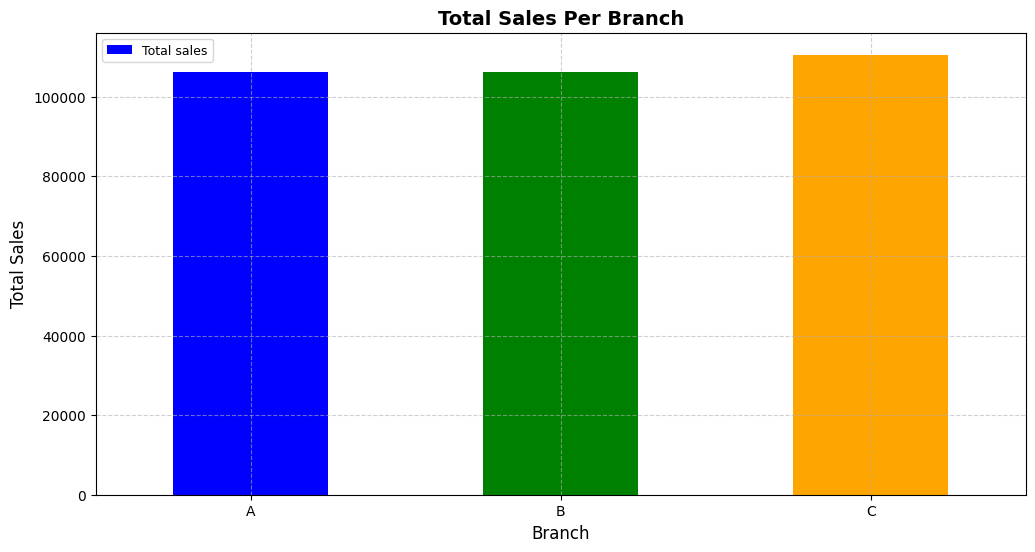

In [8]:
#Total sales per branch
total_per_branch=df.groupby('Branch')['Total'].sum()
plt.figure(figsize=(12, 6))  # Set figure size
total_per_branch.plot(kind='bar',color=['blue', 'green', 'orange'])
# Add labels and title
plt.title("Total Sales Per Branch", fontsize=14, fontweight='bold')
plt.xlabel("Branch", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.xticks(rotation=0)
# Add grid and legend
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(['Total sales'] ,fontsize=9 )
plt.show()

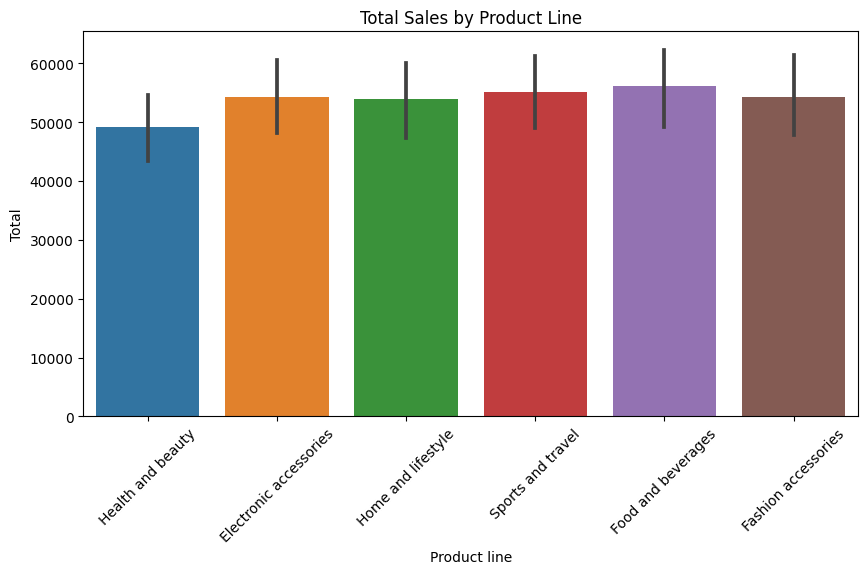

In [9]:
#Total sales by product line
plt.figure(figsize=(10, 5))  
sns.barplot(x=df["Product line"], y=df["Total"], estimator=np.sum)  
plt.xticks(rotation=45)  
plt.title("Total Sales by Product Line")  
plt.show()  


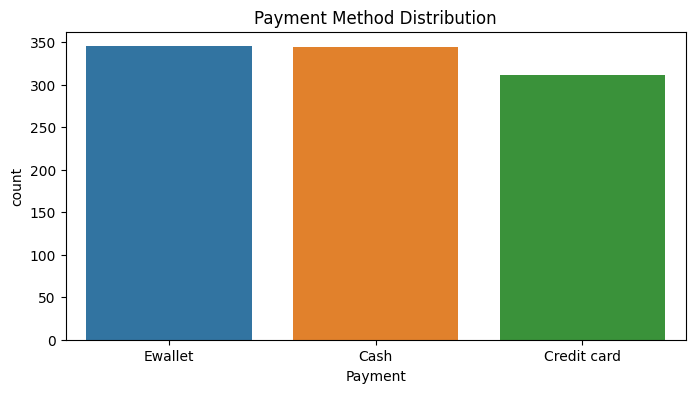

In [10]:
#pyment method distuibution
plt.figure(figsize=(8, 4))  
sns.countplot(x=df["Payment"])  
plt.title("Payment Method Distribution")  
plt.show()  


## Data Preparation For Model Training

In [11]:
#convert Category
df = pd.get_dummies(df, columns=["Branch"], drop_first=True)
df = pd.get_dummies(df, columns=["City"], drop_first=True)
df = pd.get_dummies(df, columns=["Product line"], drop_first=True)
df = pd.get_dummies(df, columns=["Payment"], drop_first=True)

In [12]:
#Leable Encoder
df['Customer type'] = df['Customer type'].map({'Member': 1, 'Normal': 0})
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


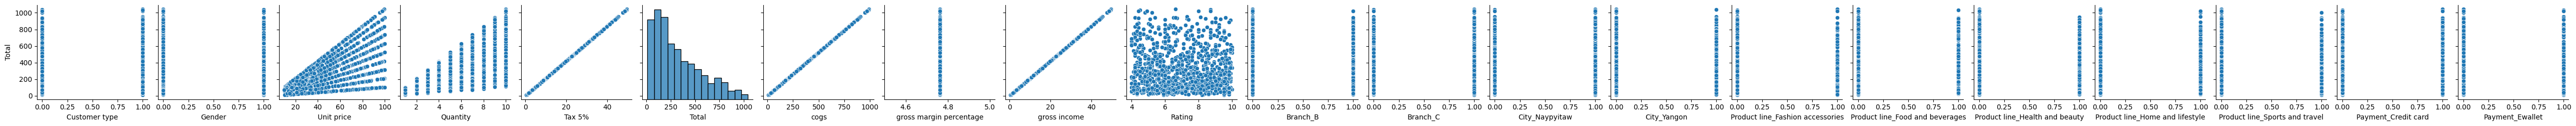

In [13]:
# Plot pairplot (Total vs. all numerical features)
sns.pairplot(df, y_vars=['Total'], height=2.5)
plt.show()


In [14]:
# Split Data
X = df.drop(columns=['Invoice ID', 'Date', 'Time','Total'])
y=df['Total']
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=88,test_size=0.33)

## Model Training & Evaluation

### Liner Regression





In [15]:
#set model and print metraces 
LR=LinearRegression()
LR.fit(X_train,y_train)
#data pred
y_pred_Test_LR=LR.predict(X_test)
y_pred_Train_LR=LR.predict(X_train)
#score
score_train_LR=LR.score(X_train, y_train)
score_test_LR=LR.score(X_test, y_test)
#cross validation
CV_LR=cross_val_score(LR,X,y,scoring='neg_mean_squared_error',cv=5)
CV_LR_mean=np.mean(CV_LR)
#Mean squared error 
MSR_Test_LR=mean_squared_error(y_test,y_pred_Test_LR)
MSR_Train_LR=mean_squared_error(y_train,y_pred_Train_LR)
#print metraces
print('Metraces for Linear Regression')
print('Train Score is:',score_train_LR)
print('Test Score is:',score_test_LR)
print('Mean Squared Error Train is:',MSR_Train_LR)
print('Mean Squared Error Test is:',MSR_Test_LR)
print('Cross Validation is:',CV_LR)
print('Mean Cross Validation is:',CV_LR_mean)


Metraces for Linear Regression
Train Score is: 1.0
Test Score is: 1.0
Mean Squared Error Train is: 5.553472451556997e-26
Mean Squared Error Test is: 5.011410537425553e-26
Cross Validation is: [-1.10622659e-25 -2.11256950e-26 -2.23604832e-26 -1.48196041e-26
 -1.81275187e-26]
Mean Cross Validation is: -3.741119200469093e-26


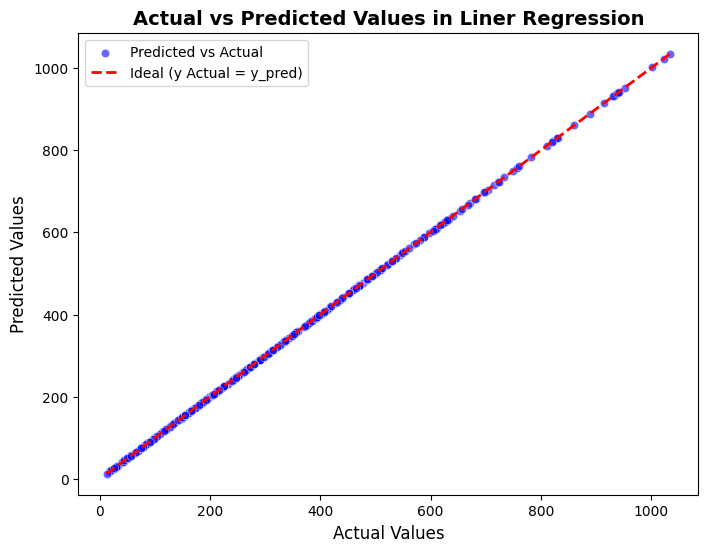

In [16]:
#Actual vs Predicted Values in Liner Regression(plot)
plt.figure(figsize=(8,6 ))
sns.scatterplot(x=y_test, y=y_pred_Test_LR, color='blue', label='Predicted vs Actual', alpha=0.6)
min_val = np.min([y_test, y_pred_Test_LR])
max_val = np.max([y_test, y_pred_Test_LR])
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='dashed', linewidth=2, label='Ideal (y Actual = y_pred)')
plt.xlabel('Actual Values',fontsize=12)
plt.ylabel('Predicted Values',fontsize=12)
plt.title('Actual vs Predicted Values in Liner Regression', fontsize=14, fontweight='bold')
plt.legend()
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


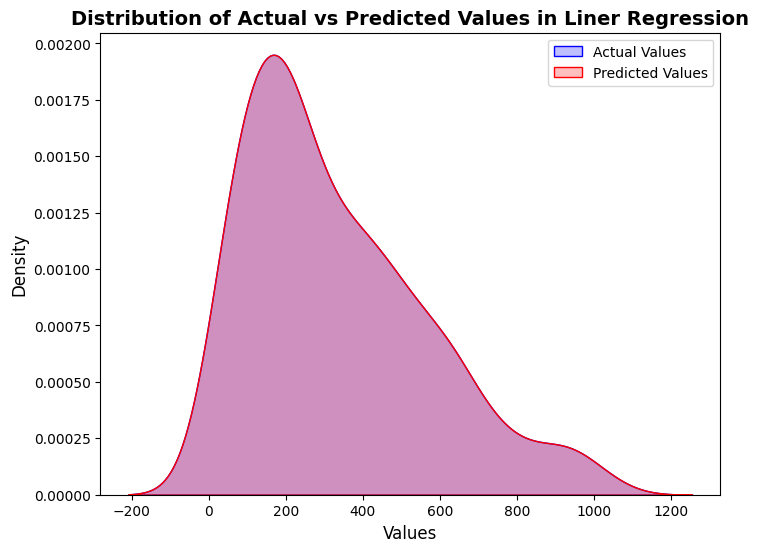

In [17]:
#Distribution of Actual vs Predicted Values in Liner Regression(plot)
plt.figure(figsize=(8, 6))
sns.kdeplot(y_test, label='Actual Values', color='blue', fill=True)
sns.kdeplot(y_pred_Test_LR, label='Predicted Values', color='red', fill=True)
plt.xlabel('Values',fontsize=12)
plt.ylabel('Density',fontsize=12)
plt.title('Distribution of Actual vs Predicted Values in Liner Regression', fontsize=14, fontweight='bold')
plt.legend()
plt.show()

### Ridge

In [18]:
#set model and print metraces 

R=Ridge()
R.fit(X_train,y_train)
#data pred
y_pred_Test_R=R.predict(X_test)
y_pred_Train_R=R.predict(X_train)
#Score
score_train_R=R.score(X_train, y_train)
score_test_R=R.score(X_test, y_test)
#cross validation
CV_R=cross_val_score(R,X,y,scoring='neg_mean_squared_error',cv=5)
CV_R_mean=np.mean(CV_R)
#Mean squared error 
MSR_Test_R=mean_squared_error(y_test,y_pred_Test_R)
MSR_Train_R=mean_squared_error(y_train,y_pred_Train_R)
#print metraces
print('Metraces for Ridge')
print('Train Score is:',score_train_R)
print('Test Score is:',score_test_R)
print('Mean Squared Error Train is:',MSR_Train_R)
print('Mean Squared Error Test is:',MSR_Test_R)
print('Cross Validation is:',CV_R)
print('Mean Cross Validation is:',CV_R_mean)


Metraces for Ridge
Train Score is: 0.9999999999999938
Test Score is: 0.9999999999999934
Mean Squared Error Train is: 3.9351701287898084e-10
Mean Squared Error Test is: 3.6007163878297407e-10
Cross Validation is: [-2.94934166e-10 -3.06297250e-10 -2.97913394e-10 -2.83922186e-10
 -3.13173114e-10]
Mean Cross Validation is: -2.992480220298608e-10


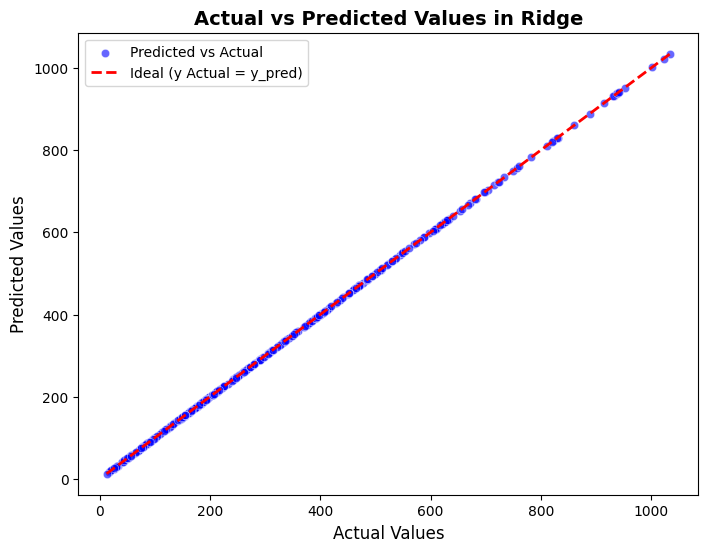

In [19]:
#Actual vs Predicted Values in Ridge(plot)
plt.figure(figsize=(8,6 ))
sns.scatterplot(x=y_test, y=y_pred_Test_R, color='blue', label='Predicted vs Actual', alpha=0.6)
min_val = np.min([y_test, y_pred_Test_R])
max_val = np.max([y_test, y_pred_Test_R])
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='dashed', linewidth=2, label='Ideal (y Actual = y_pred)')
plt.xlabel('Actual Values',fontsize=12)
plt.ylabel('Predicted Values',fontsize=12)
plt.title('Actual vs Predicted Values in Ridge', fontsize=14, fontweight='bold')
plt.legend()
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


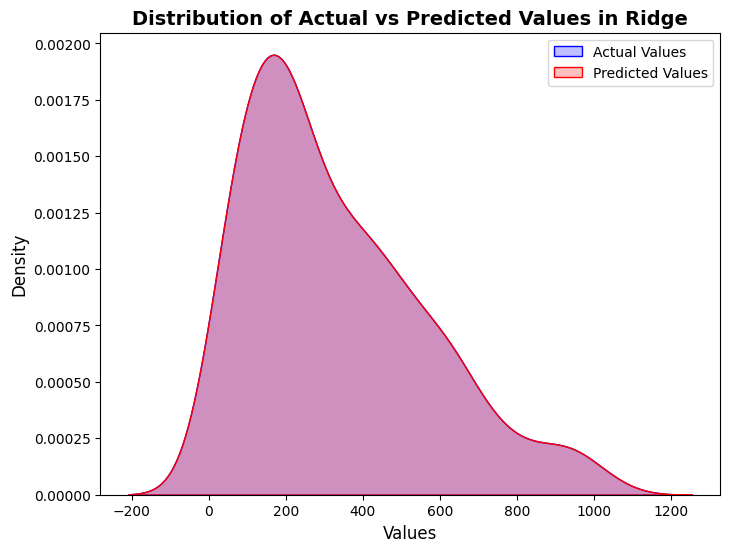

In [20]:
#Distribution of Actual vs Predicted Values in Ridge (plot)
plt.figure(figsize=(8, 6))
sns.kdeplot(y_test, label='Actual Values', color='blue', fill=True)
sns.kdeplot(y_pred_Test_R, label='Predicted Values', color='red', fill=True)
plt.xlabel('Values',fontsize=12)
plt.ylabel('Density',fontsize=12)
plt.title('Distribution of Actual vs Predicted Values in Ridge', fontsize=14, fontweight='bold')
plt.legend()
plt.show()

### Lasso

In [21]:
#set model and print metraces 

L=Lasso()
L.fit(X_train,y_train)
#data pred
y_pred_Test_L=L.predict(X_test)
y_pred_Train_L=L.predict(X_train)
#score
score_train_L=L.score(X_train, y_train)
score_test_L=L.score(X_test, y_test)
#cross validation
CV_L=cross_val_score(L,X,y,scoring='neg_mean_squared_error',cv=5)
CV_L_mean=np.mean(CV_L)
#Mean squared error 
MSR_Test_L=mean_squared_error(y_test,y_pred_Test_L)
MSR_Train_L=mean_squared_error(y_train,y_pred_Train_L)
#print metraces
print('Metraces for Lasso')
print('Train Score is:',score_train_L)
print('Test Score is:',score_test_L)
print('Mean Squared Error Train is:',MSR_Train_L)
print('Mean Squared Error Test is:',MSR_Test_L)
print('Cross Validation is:',CV_L)
print('Mean Cross Validation is:',CV_L_mean)


Metraces for Lasso
Train Score is: 0.999999999721661
Test Score is: 0.9999999997206374
Mean Squared Error Train is: 1.7517671107760034e-05
Mean Squared Error Test is: 1.5396189630984143e-05
Cross Validation is: [-2.36147236e-05 -1.42735839e-05 -1.60295111e-05 -2.13677971e-05
 -1.78077652e-05]
Mean Cross Validation is: -1.8618676158362506e-05


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.129e+03, tolerance: 4.217e+03
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.045e+04, tolerance: 4.625e+03
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.089e+04, tolerance: 5.022e

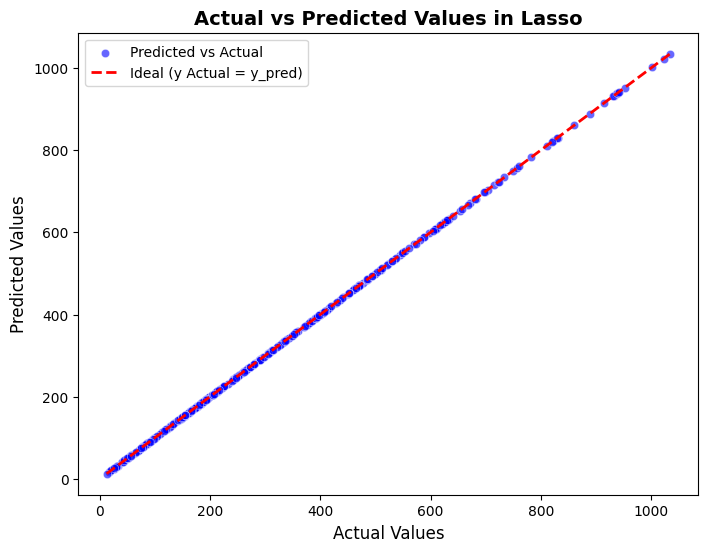

In [22]:
#Actual vs Predicted Values in Lasso(plot)
plt.figure(figsize=(8,6 ))
sns.scatterplot(x=y_test, y=y_pred_Test_L, color='blue', label='Predicted vs Actual', alpha=0.6)
min_val = np.min([y_test, y_pred_Test_L])
max_val = np.max([y_test, y_pred_Test_L])
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='dashed', linewidth=2, label='Ideal (y Actual = y_pred)')
plt.xlabel('Actual Values',fontsize=12)
plt.ylabel('Predicted Values',fontsize=12)
plt.title('Actual vs Predicted Values in Lasso', fontsize=14, fontweight='bold')
plt.legend()
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


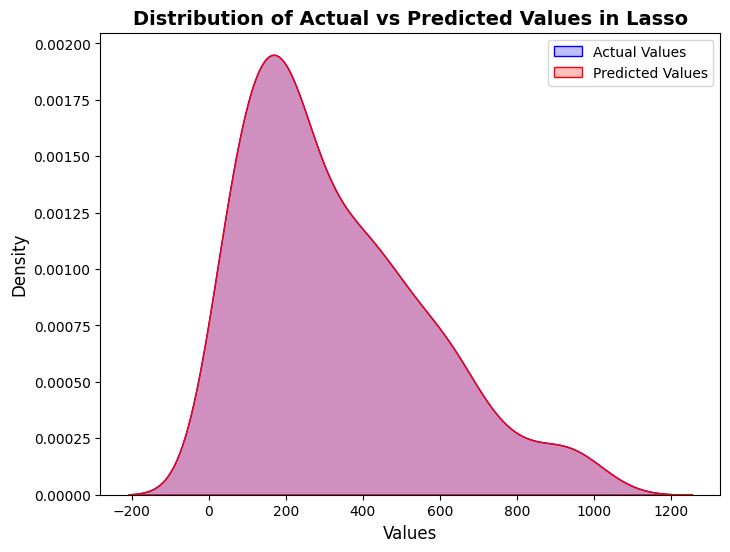

In [23]:
#Distribution of Actual vs Predicted Values in Lasso(plot)
plt.figure(figsize=(8, 6))
sns.kdeplot(y_test, label='Actual Values', color='blue', fill=True)
sns.kdeplot(y_pred_Test_L, label='Predicted Values', color='red', fill=True)
plt.xlabel('Values',fontsize=12)
plt.ylabel('Density',fontsize=12)
plt.title('Distribution of Actual vs Predicted Values in Lasso', fontsize=14, fontweight='bold')
plt.legend()
plt.show()

### Random Foreset Regressor

In [24]:
#set model and print metraces 

RFR=RandomForestRegressor()
RFR.fit(X_train,y_train)
#data pred
y_pred_Test_RFR=RFR.predict(X_test)
y_pred_Train_RFR=RFR.predict(X_train)
#Score
score_train_RFR=RFR.score(X_train, y_train)
score_test_RFR=RFR.score(X_test, y_test)
#cross validation
CV_RFR=cross_val_score(RFR,X,y,scoring='neg_mean_squared_error',cv=5)
CV_RFR_mean=np.mean(CV_RFR)
#Mean squared error 
MSR_Test_RFR=mean_squared_error(y_test,y_pred_Test_RFR)
MSR_Train_RFR=mean_squared_error(y_train,y_pred_Train_RFR)
#print metraces
print('Metraces for RandomForestRegressor')
print('Train Score is:',score_train_RFR)
print('Test Score is:',score_test_RFR)
print('Mean Squared Error Train is:',MSR_Train_RFR)
print('Mean Squared Error Test is:',MSR_Test_RFR)
print('Cross Validation is:',CV_RFR)
print('Mean Cross Validation is:',CV_RFR_mean)

Metraces for RandomForestRegressor
Train Score is: 0.9999923838749656
Test Score is: 0.9999619466336185
Mean Squared Error Train is: 0.47933185852007915
Mean Squared Error Test is: 2.0971908227788334
Cross Validation is: [-2.08329412 -1.53969961 -1.85883627 -1.80161869 -2.44752451]
Mean Cross Validation is: -1.9461946409734865


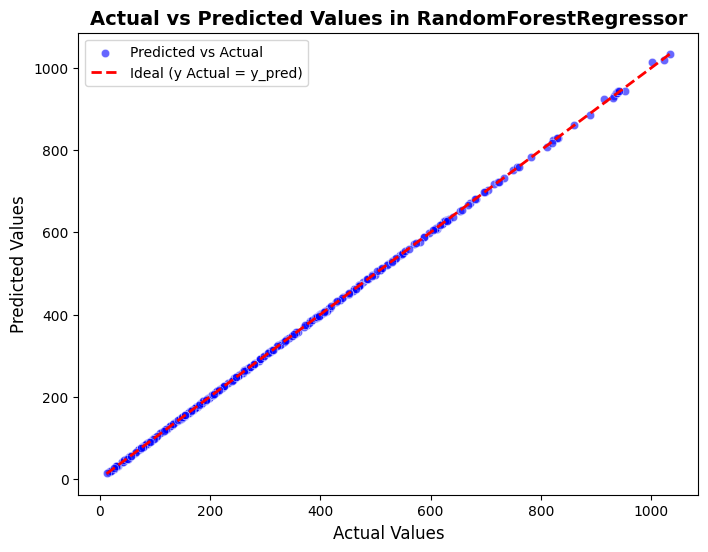

In [25]:
#Actual vs Predicted Values in RandomForestRegressor(plot)
plt.figure(figsize=(8,6 ))
sns.scatterplot(x=y_test, y=y_pred_Test_RFR, color='blue', label='Predicted vs Actual', alpha=0.6)
min_val = np.min([y_test, y_pred_Test_RFR])
max_val = np.max([y_test, y_pred_Test_RFR])
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='dashed', linewidth=2, label='Ideal (y Actual = y_pred)')
plt.xlabel('Actual Values',fontsize=12)
plt.ylabel('Predicted Values',fontsize=12)
plt.title('Actual vs Predicted Values in RandomForestRegressor', fontsize=14, fontweight='bold')
plt.legend()
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


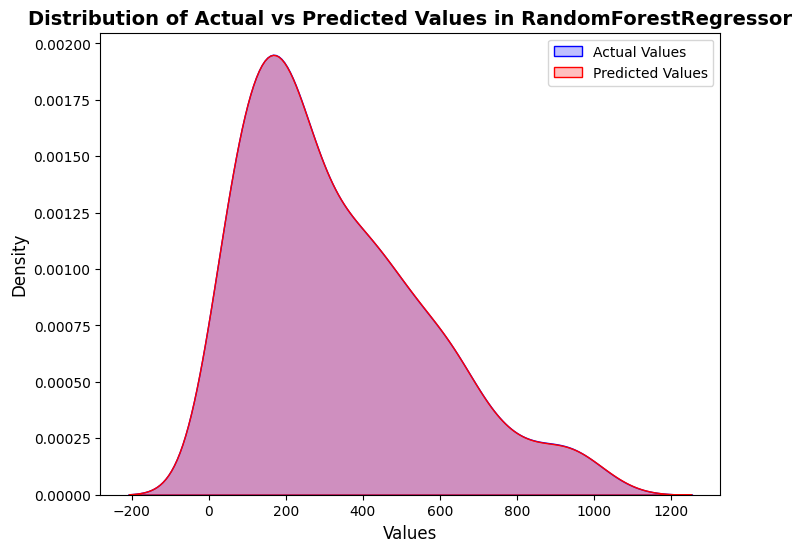

In [26]:
#Distribution of Actual vs Predicted Values in RandomForestRegressor(plot)
plt.figure(figsize=(8, 6))
sns.kdeplot(y_test, label='Actual Values', color='blue', fill=True)
sns.kdeplot(y_pred_Test_RFR, label='Predicted Values', color='red', fill=True)
plt.xlabel('Values',fontsize=12)
plt.ylabel('Density',fontsize=12)
plt.title('Distribution of Actual vs Predicted Values in RandomForestRegressor', fontsize=14, fontweight='bold')
plt.legend()
plt.show()

### Decision Tree Regressor

In [27]:
#set model and  print metraces 

DTR=DecisionTreeRegressor()
DTR.fit(X_train,y_train)
#data pred
y_pred_Test_DTR=DTR.predict(X_test)
y_pred_Train_DTR=DTR.predict(X_train)
#score
score_train_DTR=DTR.score(X_train, y_train)
score_test_DTR=DTR.score(X_test, y_test)
#cross validation
CV_DTR=cross_val_score(DTR,X,y,scoring='neg_mean_squared_error',cv=5)
CV_DTR_mean=np.mean(CV_DTR)
#Mean squared error 
MSR_Test_DTR=mean_squared_error(y_test,y_pred_Test_DTR)
MSR_Train_DTR=mean_squared_error(y_train,y_pred_Train_DTR)
#print metraces
print('Metraces for DecisionTreeRegressor')
print('Train Score is:',score_train_DTR)
print('Test Score is:',score_test_DTR)
print('Mean Squared Error Train is:',MSR_Train_DTR)
print('Mean Squared Error Test is:',MSR_Test_DTR)
print('Cross Validation is:',CV_DTR)
print('Mean Cross Validation is:',CV_DTR_mean)

Metraces for DecisionTreeRegressor
Train Score is: 1.0
Test Score is: 0.9999230818172428
Mean Squared Error Train is: 0.0
Mean Squared Error Test is: 4.239102143181825
Cross Validation is: [-6.06458018 -2.45978169 -5.99572024 -6.3798814  -5.14967717]
Mean Cross Validation is: -5.209928136000005


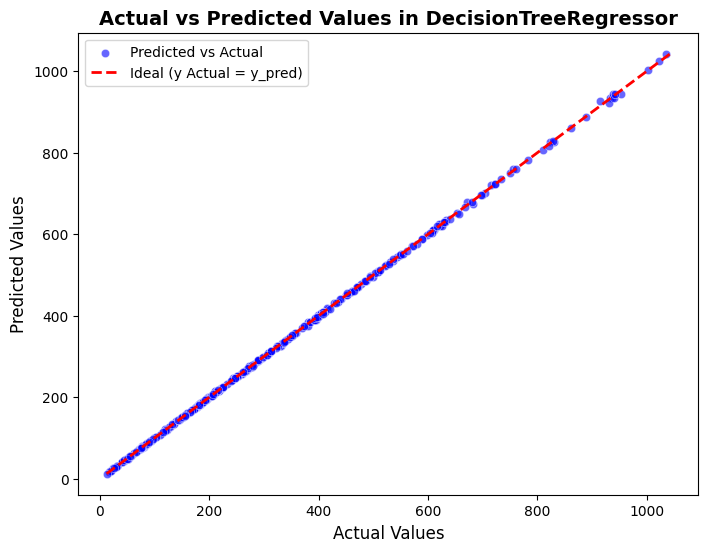

In [28]:
#Actual vs Predicted Values in DecisionTreeRegressor(plot)
plt.figure(figsize=(8,6 ))
sns.scatterplot(x=y_test, y=y_pred_Test_DTR, color='blue', label='Predicted vs Actual', alpha=0.6)
min_val = np.min([y_test, y_pred_Test_DTR])
max_val = np.max([y_test, y_pred_Test_DTR])
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='dashed', linewidth=2, label='Ideal (y Actual = y_pred)')
plt.xlabel('Actual Values',fontsize=12)
plt.ylabel('Predicted Values',fontsize=12)
plt.title('Actual vs Predicted Values in DecisionTreeRegressor', fontsize=14, fontweight='bold')
plt.legend()
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


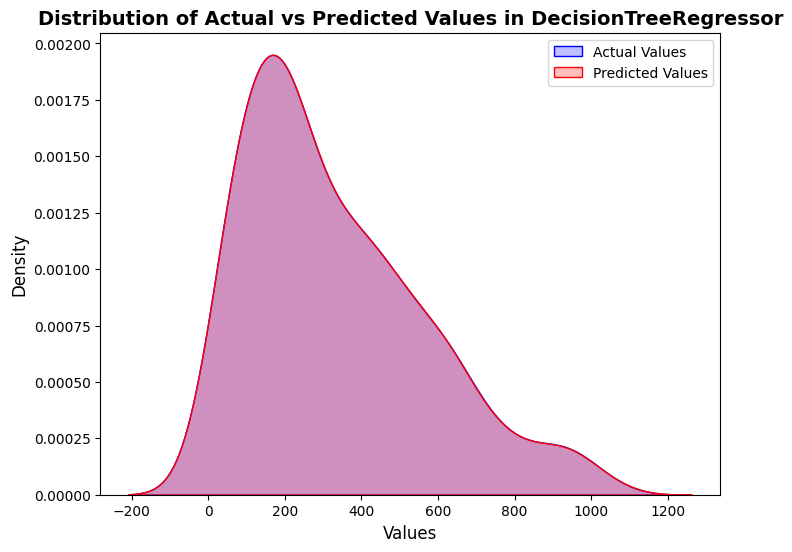

In [29]:
#Distribution of Actual vs Predicted Values in DecisionTreeRegressor(plot)
plt.figure(figsize=(8, 6))
sns.kdeplot(y_test, label='Actual Values', color='blue', fill=True)
sns.kdeplot(y_pred_Test_DTR, label='Predicted Values', color='red', fill=True)
plt.xlabel('Values',fontsize=12)
plt.ylabel('Density',fontsize=12)
plt.title('Distribution of Actual vs Predicted Values in DecisionTreeRegressor',fontsize=14, fontweight='bold')
plt.legend()
plt.show()

### Compare Models With Multiple Metrics

In [30]:
# Define metrics for each model
models = ["Linear Regression", "Ridge Regression", "Lasso Regression", "Random Forest Regressor", "Decision Tree Regressor"]

train_scores = [score_train_LR, score_train_R, score_train_L, score_train_RFR, score_train_DTR]
test_scores = [score_test_LR, score_test_R, score_test_L, score_test_RFR, score_test_DTR]
cv_scores = [CV_LR_mean, CV_R_mean, CV_L_mean, CV_RFR_mean, CV_DTR_mean]
mse_train = [MSR_Train_LR, MSR_Train_R, MSR_Train_L, MSR_Train_RFR, MSR_Train_DTR]
mse_test = [MSR_Test_LR, MSR_Test_R, MSR_Test_L, MSR_Test_RFR, MSR_Test_DTR]

# Create a DataFrame to store the results
df_comparison = pd.DataFrame({
    "Model": models,
    "Train Score": train_scores,
    "Test Score": test_scores,
    "CV Score": cv_scores,
    "MSE Train": mse_train,
    "MSE Test": mse_test
})

# Sort models by Test Score (Descending Order)
df_comparison = df_comparison.sort_values(by="Test Score", ascending=False)

# Print the table
print("Model Performance Comparison:\n")
print(df_comparison.to_string())


Model Performance Comparison:

                     Model  Train Score  Test Score      CV Score     MSE Train      MSE Test
0        Linear Regression     1.000000    1.000000 -3.741119e-26  5.553472e-26  5.011411e-26
1         Ridge Regression     1.000000    1.000000 -2.992480e-10  3.935170e-10  3.600716e-10
2         Lasso Regression     1.000000    1.000000 -1.861868e-05  1.751767e-05  1.539619e-05
3  Random Forest Regressor     0.999992    0.999962 -1.946195e+00  4.793319e-01  2.097191e+00
4  Decision Tree Regressor     1.000000    0.999923 -5.209928e+00  0.000000e+00  4.239102e+00


In [31]:
# print train_scoers useing (Descending Order)
train_scores = {
    "Linear Regression": score_train_LR,
    "Ridge Regression": score_train_R,
    "Lasso Regression": score_train_L,
    "Random Forest Regressor": score_train_RFR,
    "Decision Tree Regressor": score_train_DTR
}
sorted_train_scores = sorted(train_scores.items(), key=lambda x: x[1], reverse=True)
print("Models Sorted by Training Score (Descending Order):")
for model, score in sorted_train_scores:
    print(f"{model}: {score:.16f}")
print('--------------------------------------------------')
# print test_scoers useing (Descending Order)
test_scores = {
    "Linear Regression": score_test_LR,
    "Ridge Regression": score_test_R,
    "Lasso Regression": score_test_L,
    "Random Forest Regressor": score_test_RFR,
    "Decision Tree Regressor": score_test_DTR
}
sorted_test_scores = sorted(test_scores.items(), key=lambda x: x[1], reverse=True)
print("Models Sorted by Testing Score (Descending Order):")
for model, score in sorted_test_scores:
    print(f"{model}: {score:.16f}")
print('--------------------------------------------------')

# print mean square error train useing (Closest to Zero)
mean_square_error_train = {
    "Linear Regression": MSR_Train_LR,
    "Ridge Regression": MSR_Train_R,
    "Lasso Regression":MSR_Train_L,
    "Random Forest Regressor": MSR_Train_RFR,
    "Decision Tree Regressor":MSR_Train_DTR
}
sorted_mean_square_error= sorted(mean_square_error_train.items(), key=lambda x: abs(x[1]))
print("Models Sorted by Mean Square Erorr Training (Closest to Zero):")
for model, score in sorted_mean_square_error:
    print(f"{model}: {score:.16f}")
print('--------------------------------------------------')
# print mean square error test useing (Closest to Zero)
mean_square_error_test = {
    "Linear Regression": MSR_Test_LR,
    "Ridge Regression": MSR_Test_R,
    "Lasso Regression": MSR_Test_L,
    "Random Forest Regressor":  MSR_Test_RFR,
    "Decision Tree Regressor": MSR_Test_DTR
}
sorted_mean_square_error_test = sorted(train_scores.items(), key=lambda x: abs(x[1]))
print("Models Sorted by Mean Square Error Testing (Closest to Zero):")
for model, score in sorted_mean_square_error_test:
    print(f"{model}: {score:.16f}")
print('--------------------------------------------------')
# print cross validation useing (Closest to Zero)
CV_mean = {
    "Linear Regression": CV_LR_mean,
    "Ridge Regression": CV_R_mean,
    "Lasso Regression": CV_L_mean,
    "Random Forest Regressor": CV_RFR_mean,
    "Decision Tree Regressor": CV_DTR_mean
}
sorted_CV_mean = sorted(CV_mean.items(), key=lambda x: abs(x[1]))
print(" Models Sorted by Mean of Cross-Validation Score (Closest to Zero):")
for model, score in sorted_CV_mean:
    print(f"{model}: {score:.16f}")  # Showing 16 decimal places for precision


Models Sorted by Training Score (Descending Order):
Linear Regression: 1.0000000000000000
Decision Tree Regressor: 1.0000000000000000
Ridge Regression: 0.9999999999999938
Lasso Regression: 0.9999999997216610
Random Forest Regressor: 0.9999923838749656
--------------------------------------------------
Models Sorted by Testing Score (Descending Order):
Linear Regression: 1.0000000000000000
Ridge Regression: 0.9999999999999934
Lasso Regression: 0.9999999997206374
Random Forest Regressor: 0.9999619466336185
Decision Tree Regressor: 0.9999230818172428
--------------------------------------------------
Models Sorted by Mean Square Erorr Training (Closest to Zero):
Decision Tree Regressor: 0.0000000000000000
Linear Regression: 0.0000000000000000
Ridge Regression: 0.0000000003935170
Lasso Regression: 0.0000175176711078
Random Forest Regressor: 0.4793318585200791
--------------------------------------------------
Models Sorted by Mean Square Error Testing (Closest to Zero):
Random Forest Regre